In [14]:
%load_ext autoreload
%autoreload 2

import torch
import os
import encoding_model
import numpy as np
import glob
import matplotlib.pyplot as plt

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [2]:
def rescale_channel(channel):
    min_val = np.min(channel)
    max_val = np.max(channel)
    if max_val - min_val == 0:
        return np.zeros_like(channel)  # min and max are the same -- degenerate trace (no data)
    return (channel - min_val) / (max_val - min_val)

In [3]:
def load_and_preprocess_data(data_dir: str, label: int):
    all_files = glob.glob(data_dir)
    full_trajectory = []
    full_labels = []

    for file in all_files:
        data = np.genfromtxt(file)
        green = data[:, 1]
        green = rescale_channel(green)
        red = data[:, 2]
        red = rescale_channel(red)
        blue = data[:, 3]
        blue = rescale_channel(blue)
        trajectory = np.stack((green, blue, red))  # shape (3, T)

        full_trajectory.append(trajectory)
        full_labels.append(np.array(label))

    return full_trajectory, full_labels

In [4]:
exp_data_461 = "/home/jzhou59/data_mjohn218/jzhou59/fret_data/expData_3colorFRET/expCondition_461/group1/*"
exp_461_trajs, exp_461_labels = load_and_preprocess_data(exp_data_461, label=0) 

exp_data_lowMg2 = "/home/jzhou59/data_mjohn218/jzhou59/fret_data/expData_3colorFRET/expCondition_lowMg2/*"
exp_lowMg2_trajs, exp_lowMg2_labels = load_and_preprocess_data(exp_data_lowMg2, label=1)

full_trajectory = exp_461_trajs + exp_lowMg2_trajs
full_labels = exp_461_labels + exp_lowMg2_labels

In [5]:
ds = encoding_model.TimeSeriesDataset(full_trajectory, full_labels)

In [6]:
dataloader = encoding_model.TimeSeriesDataloader(ds, batch_size=16, shuffle=True)

In [7]:
batch, label = next(iter(dataloader))
batch.shape

torch.Size([16, 3, 631])

In [13]:
classifier, epoch_losses = encoding_model.train(ds, 1000)

Epoch 1/1000, Loss: 0.7327
Epoch 2/1000, Loss: 0.7288
Epoch 3/1000, Loss: 0.7251
Epoch 4/1000, Loss: 0.7211
Epoch 5/1000, Loss: 0.7179
Epoch 6/1000, Loss: 0.7141
Epoch 7/1000, Loss: 0.7102
Epoch 8/1000, Loss: 0.7057
Epoch 9/1000, Loss: 0.7004
Epoch 10/1000, Loss: 0.6937
Epoch 11/1000, Loss: 0.6880
Epoch 12/1000, Loss: 0.6794
Epoch 13/1000, Loss: 0.6705
Epoch 14/1000, Loss: 0.6665
Epoch 15/1000, Loss: 0.6590
Epoch 16/1000, Loss: 0.6529
Epoch 17/1000, Loss: 0.6517
Epoch 18/1000, Loss: 0.6461
Epoch 19/1000, Loss: 0.6433
Epoch 20/1000, Loss: 0.6402
Epoch 21/1000, Loss: 0.6319
Epoch 22/1000, Loss: 0.6285
Epoch 23/1000, Loss: 0.6230
Epoch 24/1000, Loss: 0.6151
Epoch 25/1000, Loss: 0.5999
Epoch 26/1000, Loss: 0.5987
Epoch 27/1000, Loss: 0.5994
Epoch 28/1000, Loss: 0.6049
Epoch 29/1000, Loss: 0.5987
Epoch 30/1000, Loss: 0.5885
Epoch 31/1000, Loss: 0.5748
Epoch 32/1000, Loss: 0.5690
Epoch 33/1000, Loss: 0.5795
Epoch 34/1000, Loss: 0.5524
Epoch 35/1000, Loss: 0.5663
Epoch 36/1000, Loss: 0.5443
E

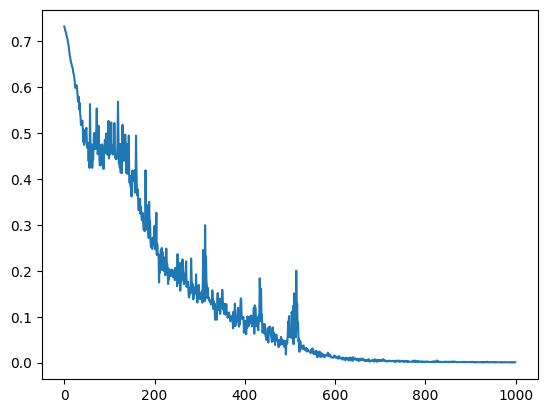

In [15]:
plt.plot(range(0, len(epoch_losses)), epoch_losses)